In [1]:
import os
import sys
import numpy as np
import matplotlib.pyplot as plt
import json


# All imported in ic_visualization.py:
import requests #for url downloading
from astropy.io import fits
from astropy.coordinates import SkyCoord
from astropy import units as u
from astropy.table import QTable
import astropy_healpix as ah
from regions import PointSkyRegion
import healpy as hp
import mhealpy as mhp
from mhealpy import HealpixMap
import ligo.skymap.plot
from ligo.skymap.io.fits import read_sky_map

sys.path.insert(1, '../../') #check where your ic_visualization.py file is, add path to it
# from ic_visualization import plot_IC_alert, write_new_yaml, plot_zoomed_IC_alert, select_pixels, check_source_in_map

from ic_processing import read_map
from ic_visualization import plot_full_map
from ic_yaml import write_new_yaml



from params import p

import mhealpy as mh



/Users/cristozilleruelo/.local/share/mamba/envs/AMPEL/lib/python3.14/site-packages/igwn_ligolw/lsctables.py:57: UserWarning: Wswiglal-redir-stdio:

SWIGLAL standard output/error redirection is enabled in IPython.
This may lead to performance penalties. To disable locally, use:

with lal.no_swig_redirect_standard_output_error():
    ...

To disable globally, use:

lal.swig_redirect_standard_output_error(False)

Note however that this will likely lead to error messages from
LAL functions being either misdirected or lost when called from
Jupyter notebooks.

To suppress this warning, use:

import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")
import lal

  import lal


In [2]:
from hop import Stream
from hop.io import StartPosition
#https://hop-client.readthedocs.io/en/latest/user/quickstart.html

stream = Stream(start_at=StartPosition.EARLIEST, until_eos=True)
alerts = []
with stream.open("kafka://kafka.scimma.org/gcn.notices.icecube.gold_bronze_track_alerts", "r") as s:
    for message in s:
         # print(message.content)
        alerts.append(message.content)


In [3]:
print('latest alert: ')
alerts[-1]

latest alert: 


{'$schema': 'https://gcn.nasa.gov/schema/v6.1.1/gcn/notices/icecube/single_neutrino_alerts.schema.json',
 'mission': 'IceCube',
 'instrument': 'IC86',
 'messenger': 'Neutrino',
 'pipeline': 'Bronze Track Alert',
 'record_number': 1,
 'event_name': ['IceCube-261123A'],
 'id': ['143530_34667334'],
 'alert_datetime': '2026-11-23T08:27:36.7Z',
 'alert_type': 'update',
 'alert_tense': 'current',
 'alert_topology': 'Track',
 'number_of_events': 1,
 'ra': 320.45,
 'dec': 24.58,
 'ra_dec_error': 1.47,
 'containment_probability': 0.9,
 'systematic_included': True,
 'healpix_url': 'https://roc-2.icecube.wisc.edu/public/alerts/IceCube-261123A_skymap_probdensity_multiorder.fits.gz',
 'trigger_time': '2026-11-23T06:54:16.990Z',
 'nu_energy': 145.05,
 'p_astro': 0.4571,
 'far': 3.7898e-08}

In [4]:
#ampel test alert!
# alert_str = '{"$schema": "https://gcn.nasa.gov/schema/v6.1.0/gcn/notices/icecube/single_neutrino_alerts.schema.json", "mission": "IceCube", "instrument": "IC86", "messenger": "Neutrino", "pipeline": "Bronze Track Alert", "record_number": 2, "event_name": ["IceCube-260115A"], "id": ["141917_80302474_1"], "alert_datetime": "2026-01-15T17:33:18.0Z", "alert_type": "update", "alert_tense": "current", "alert_topology": "Track", "number_of_events": 1, "ra": 145.77, "dec": 12.41, "ra_dec_error": "2.2", "containment_probability": 0.9, "systematic_included": true, "healpix_url": "https://roc-2.icecube.wisc.edu/public/alerts/IceCube-260115A_skymap_probdensity_multiorder.fits.gz", "trigger_time": "2026-01-15T17:32:35.711Z", "nu_energy": 122.22, "p_astro": 0.3521, "far": "6.511e-08"}'

# alert_str = '{"$schema": "https://gcn.nasa.gov/schema/v6.1.1/gcn/notices/icecube/single_neutrino_alerts.schema.json", "mission": "IceCube", "instrument": "IC86", "messenger": "Neutrino", "pipeline": "Bronze Track Alert", "record_number": 1, "event_name": ["IceCube-260217A"], "id": ["142135_80851825"], "alert_datetime": "2026-02-17T06:29:00.0Z", "alert_type": "update", "alert_tense": "current", "alert_topology": "Track", "number_of_events": 1, "ra": 75.89, "dec": 16.63, "ra_dec_error": 0.68, "containment_probability": 0.9, "systematic_included": true, "healpix_url": "https://roc-2.icecube.wisc.edu/public/alerts/IceCube-260217A_skymap_probdensity_multiorder.fits.gz", "trigger_time": "2026-02-17T05:55:24.519Z", "nu_energy": 107.32, "p_astro": 0.317, "far": 8.8409e-08}'
# test_alert = '{"$schema": "https://gcn.nasa.gov/schema/v6.1.1/gcn/notices/icecube/single_neutrino_alerts.schema.json", "mission": "IceCube", "instrument": "IC86", "messenger": "Neutrino", "pipeline": "Gold Track Alert", "record_number": 1, "event_name": ["IceCube-140506L"], "id": ["20878_16911"], "alert_datetime": "2026-02-16T09:59:28.859239Z", "alert_type": "update", "alert_tense": "injection", "alert_topology": "Track", "number_of_events": 1, "ra": 75.68, "dec": 14.48, "ra_dec_error": 0.57, "containment_probability": 0.9, "systematic_included": true, "healpix_url": "https://roc.icecube.wisc.edu/public/alerts/injected/IceCube-140506L_skymap_probdensity_multiorder.fits.gz", "trigger_time": "2026-02-16T08:58:57.979608Z", "nu_energy": 177.39, "p_astro": 0.5143, "far": 3.54e-08}'
# #we need the alert format in json to get the hpx map url
# alert = json.loads(alert_str)
# test_alert = json.loads(test_alert)


In [5]:
# we get the latest alert
alert = alerts[-1]
# alert = [a for a in alerts if 'IceCube-260805A' == a['event_name'][0]][1]
alert.keys()

dict_keys(['$schema', 'mission', 'instrument', 'messenger', 'pipeline', 'record_number', 'event_name', 'id', 'alert_datetime', 'alert_type', 'alert_tense', 'alert_topology', 'number_of_events', 'ra', 'dec', 'ra_dec_error', 'containment_probability', 'systematic_included', 'healpix_url', 'trigger_time', 'nu_energy', 'p_astro', 'far'])

In [6]:
source = [
    {
        'name': 'ZTF26aalixdi',
        'ra': 293.228321,  
        'dec': -15.117979
    },
    {
        'name': 'ZTF26abfurzw',
        'ra':  292.865382, 
        'dec':  -15.134462
    }
]

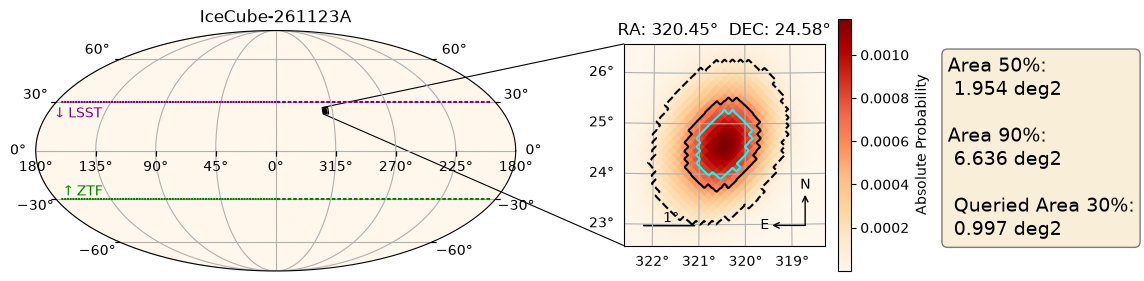

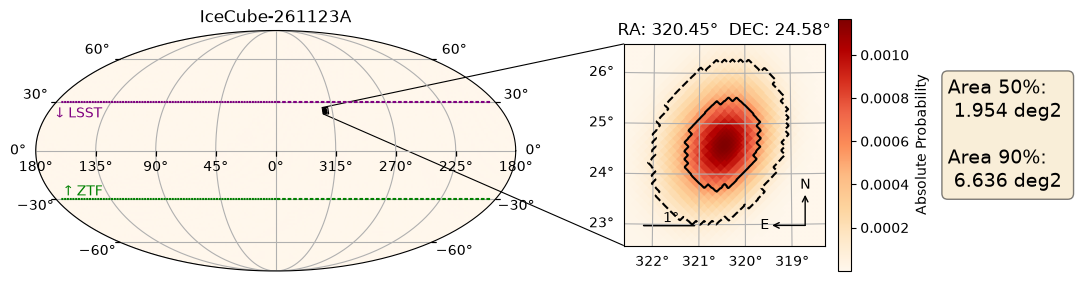

In [7]:

skymap = read_map(alert['healpix_url'])
# map_path, A_90, m = plot_IC_alert(alert['healpix_url'], r=5, plot_prob_density=False) 
map_path, A_90, m = plot_full_map(skymap, r=2, plot_prob_density=False, p_value=0.3)
map_path, A_90, m = plot_full_map(skymap, r=2, plot_prob_density=False)


# map_path, A_90, m = plot_IC_alert(alert['healpix_url'], r=1.5, plot_prob_density=False, plot_source=source)
# map_path, A_90, m = plot_IC_alert(alert['healpix_url'], r=1, plot_prob_density=True, plot_source=source)



# test_path = plot_IC_alert(test_alert['healpix_url'],r=2, save_dir='', normalize=True)
# map_path = plot_IC_alert('/Users/cristozillerplot_IC_alert(alert['healpix_url'],r=2, save_dir='')uelo/Ampel-HU-astro/RubiCube/ic_alerts/IceCube-251111L_skymap_probdensity_multiorder.fits.gz',
#                          save_dir='')

### Write YAML file

In [8]:
# path_yaml = '/Users/cristozilleruelo/Rubicube-Ampel-HU-astro/Rubicube/ampel job files/ic_alert_ZTF_processor.yaml'
save_path = '/Users/cristozilleruelo/Rubicube-Ampel-HU-astro/Rubicube/ampel job files/TEST_ic_alert_ZTF_processor.yaml'
write_new_yaml(alert, save_path, save_name=save_path)


'/Users/cristozilleruelo/Rubicube-Ampel-HU-astro/Rubicube/ampel job files/TEST_ic_alert_ZTF_processor.yaml'

## Debug

In [9]:
from ic_processing import get_moc_map_metadata, read_map, get_map_area
from ic_visualization import plot_zoomed_IC_alert

In [10]:
map = read_map(alert['healpix_url'])
map_metadata = get_moc_map_metadata(map['skymap'])
get_map_area(map)


<Quantity 6.63566538 deg2>

/Users/cristozilleruelo/Rubicube-Ampel-HU-astro/Rubicube/notebooks/Realtime/../../ic_visualization.py:274: UserWarning: Legend does not support handles for QuadContourSet instances.
See: https://matplotlib.org/stable/tutorials/intermediate/legend_guide.html#implementing-a-custom-legend-handler
  handles, labels = ax.get_legend_handles_labels()


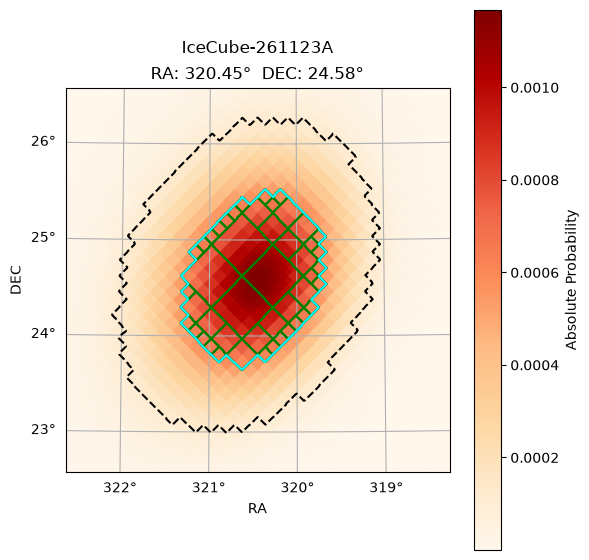

In [11]:
healpix_regions = [{'nside': 128, 'pixels': [50943, 51114, 52309, 52480]}, {'nside': 256, 'pixels': [203763, 203766, 203767, 203769, 203771, 204450, 209233, 209235, 209244, 209245, 209247, 209928, 209929, 209930]}, {'nside': 512, 'pixels': [815058, 815059, 815062, 815063, 815073, 815075, 815081, 815083, 817794, 817806, 817848, 817850, 836929, 836931, 836937, 836964, 836965, 836967, 836984, 836985, 836987, 839696, 839698, 839704, 839706, 839724, 839725, 839726, 839728]}]

plot_zoomed_IC_alert(map, save_dir='', show_fig=False, 
                    debug=healpix_regions, r=2, p_value=0.5)

In [12]:
# # Writing a new ampel job file
ampel_job_file = 'ampel job files/ic_alert_ZTF_processor.yaml'
write_new_yaml(alert, ampel_job_file, save_name='ampel job files/ic_alert_ZTF_processor.yaml')

'/Users/cristozilleruelo/Rubicube-Ampel-HU-astro/RubiCube/ampel job files/ic_alert_ZTF_processor.yaml'

In [13]:
# source_ra = 243.72
# source_dec = 6.69
# check_source_in_map(source_ra, source_dec, alert['healpix_url'], r=1)

In [14]:
skymap


{'skymap': <QTable length=5385>
   UNIQ     PROBDENSITY    
               1 / sr      
  int64       float64      
 ------- ------------------
 7542099 1168.9245984308845
 7542097 1166.4232208323026
 7542105  1164.212961744616
 7542098  1163.670395644955
 7542102 1162.9421672667547
 7542096 1162.6628575773725
 7542108 1159.7526882500954
 7542100 1159.0301735795954
 7542104  1157.435438934917
     ...                ...
    1893                0.0
    4072                0.0
    1510                0.0
    3757                0.0
    1889                0.0
    2941                0.0
    3451                0.0
    1466                0.0
    2554                0.0,
 'header': XTENSION= 'BINTABLE'           / binary table extension                         
 BITPIX  =                    8 / array data type                                
 NAXIS   =                    2 / number of array dimensions                     
 NAXIS1  =                   16 / length of dimension 1            

In [15]:
# def get_hpx_regions(skymap, p_value, path=None):
#         if path is not None:
#             skymap = QTable.read('/Users/cristozilleruelo/Ampel-HU-astro/RubiCube/ic_alerts_temp/IceCube-261113A_skymap_probdensity_multiorder.fits.gz')
#             print(skymap)
#         skymap.sort("PROBDENSITY", reverse=True)
        
#         level, ipix = ah.uniq_to_level_ipix(skymap["UNIQ"])
#         nside = ah.level_to_nside(level)
    
    
#         prob_density = skymap['PROBDENSITY']
#         pixel_area = ah.nside_to_pixel_area(nside)
    
#         prob = pixel_area * prob_density
        
#         cumprob = np.cumsum(prob)
#         i_region = cumprob.searchsorted(p_value)
        
#         selected_nside = nside[:i_region]
#         selected_ipix = ipix[:i_region]
        
#         nside_selection = list(set(selected_nside)) 
#         masked_dict = {nside_i: [] for nside_i in nside_selection}
        
#         for i in range(len(selected_nside)):
#             masked_dict[selected_nside[i]].append(int(selected_ipix[i]))
    
#         masked_list = []
#         for nside_i in masked_dict.keys():
#             masked_list.append({
#                 'nside': int(nside_i),
#                 'pixels': masked_dict[nside_i]
#             })
            
#         return masked_list

In [16]:
# get_hpx_regions(skymap['skymap'], 0.99)

In [17]:
# map_path = '/Users/cristozilleruelo/Ampel-HU-astro/RubiCube/ic_alerts_temp/IceCube-261113A_skymap_probdensity_multiorder.fits.gz'

# skymap_test = read_map(map_path)
# plot_full_map(skymap_test, save_dir='', r=0.5)

In [18]:
# get_hpx_regions(None, 0.1, path=map_path)

In [19]:
# get_hpx_regions(skymap_test['skymap'], 0.9)